# Classification sensitivity to the fixed query value

We use the teacher–student classification task of `fig_05_teacher_student_classification.ipynb` with the training-set size fixed at $N_{\rm train}=256$ and ask how precisely the student's fixed query must match the teacher query $\boldsymbol f^\star$. Panel (a) of the figure scans the predeclared path $\boldsymbol f(\lambda)=\lambda\boldsymbol f^\star$, which contains no query ($\lambda=0$), the correct query ($\lambda=1$) and the wrong query ($\lambda=2$). Panel (b) scans small mismatches $\delta=\lVert\boldsymbol f-\boldsymbol f^\star\rVert_2$ around $\boldsymbol f^\star$ and locates the mismatch $\delta_{1\%}$ beyond which the accuracy drops by more than one percentage point.

For every candidate query the student is retrained from scratch. Teachers, training and test points, optimization budgets and initial parameters are paired across query values; folds are averaged within teachers, and uncertainty is obtained by resampling teachers. The primary metric is the test balanced accuracy.

**Outputs.** `figures/fig_06_query_value_sensitivity.pdf` (and `.png`) — global and local query scans; `results/query_sensitivity/` — raw fits, the numerical configuration, the teacher-bootstrap summaries and the tolerance $\delta_{1\%}$, all tagged with the run identifier `RUN_ID` (`ff678e764ac1` for the paper run).

**Runtime.** With the cached results in `results/query_sensitivity/` the notebook runs in under a minute. Recomputing from scratch takes several hours on a CPU (10 teachers $\times$ 4 folds $\times$ 121 queries $=4840$ fits): delete `results/query_sensitivity/`, or set `PROFILE = "smoke"` for a quick pipeline check whose figure carries a `_smoke` suffix. Fits already in the raw results file are skipped, so an interrupted run continues where it stopped.

## Setup

We import the libraries, enable double precision in JAX and decide how figure text is typeset: with LaTeX when a working installation is found, otherwise with matplotlib's mathtext (setting the environment variable `USE_TEX=0` forces the fallback).

In [1]:
from dataclasses import dataclass
from pathlib import Path
import hashlib
import json
import os
import shutil
import subprocess
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import jax
import jax.numpy as jnp
from scipy.optimize import minimize

jax.config.update("jax_enable_x64", True)


def latex_is_usable():
    """True if this installation can serve matplotlib's usetex."""
    if shutil.which("latex") is None or shutil.which("dvipng") is None:
        return False
    try:
        completed = subprocess.run(
            ["kpsewhich", "latex.ltx"],
            capture_output=True,
            timeout=30,
            check=False,
        )
    except (OSError, subprocess.SubprocessError):
        return False
    return completed.returncode == 0 and bool(completed.stdout.strip())


# Honour USE_TEX=1 (the default) only if LaTeX is usable; otherwise fall back
# to mathtext with the Computer Modern font set.
USE_TEX_REQUESTED = os.environ.get("USE_TEX", "1") == "1"
USE_TEX = USE_TEX_REQUESTED and latex_is_usable()

The plotting style is the compact single-column style shared by all figures.

In [2]:
mpl.rcParams.update(
    {
        "text.usetex": USE_TEX,
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}",
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "axes.linewidth": 0.6,
        "axes.spines.top": True,
        "axes.spines.right": True,
        "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.minor.width": 0.4,
        "ytick.minor.width": 0.4,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "legend.fontsize": 6.7,
        "legend.handlelength": 1.8,
        "legend.columnspacing": 1.0,
        "lines.linewidth": 1.3,
        "savefig.bbox": None,
    }
)

## Configuration

The circuit constants are those of the teacher–student classification notebook: `BLOCK = "ry"` gives eight trainable parameters, the wrong query is `WRONG_SCALE` times $\boldsymbol f^\star$, and `BETA` is the logit scale $\beta$ of the classifier. The `paper` profile fixes $N_{\rm train}=256$, the largest training-set size of the learning-curve experiment, where the accuracy has saturated; its teachers and data seeds match that experiment. The global scan uses `global_points` values of $\lambda$, and the local scan `local_deltas` radii between `local_delta_min` and `local_delta_max` in `local_directions` directions each. The `smoke` profile is a quick end-to-end check.

In [3]:
N_QUBITS = 2
N_LAYERS = 2
BLOCK = "ry"
F_STAR_PAIR = np.array([np.pi / 4, np.pi / 3])
WRONG_SCALE = 2.0
BETA = 5.0

PROFILE = "paper"
PROFILES = {
    "smoke": dict(
        n_teachers=1,
        n_folds=1,
        n_train=32,
        n_test=1000,
        n_probe=2000,
        n_restarts=2,
        adam_steps=100,
        adam_lr=0.035,
        polish_top=1,
        polish_maxiter=50,
        global_points=5,
        local_deltas=2,
        local_directions=4,
        local_delta_min=1e-3,
        local_delta_max=1e-1,
        bootstrap_samples=200,
    ),
    "paper": dict(
        n_teachers=10,
        n_folds=4,
        n_train=256,
        n_test=20000,
        n_probe=20000,
        n_restarts=12,
        adam_steps=1500,
        adam_lr=0.03,
        polish_top=2,
        polish_maxiter=400,
        global_points=33,
        local_deltas=11,
        local_directions=8,
        local_delta_min=1e-4,
        local_delta_max=5e-1,
        bootstrap_samples=5000,
    ),
}
if PROFILE not in PROFILES:
    raise ValueError(f"unknown PROFILE={PROFILE!r}")
P = PROFILES[PROFILE]

Teachers are selected with the same predeclared criteria as in the learning-curve experiment, and all random streams derive from `BASE_SEED`. `ACCURACY_DROP` is the accuracy loss that defines the tolerance $\delta_{1\%}$.

In [4]:
TEACHER_SEEDS = list(range(P["n_teachers"]))
BALANCE = (0.4, 0.6)
MIN_NONSEP = 0.2
MAX_TEACHER_DRAWS = 4000
BASE_SEED = 1729
ACCURACY_DROP = 0.01

RESULTS_DIR = Path("../results/query_sensitivity")
FIGURES_DIR = Path("../figures")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(
    f"profile={PROFILE} | block={BLOCK} | teachers={P['n_teachers']} | "
    f"folds={P['n_folds']} | N_train={P['n_train']} | usetex={USE_TEX}"
)
if PROFILE != "paper":
    print("SMOKE PROFILE: quick pipeline check only; numbers are not meaningful.")

profile=paper | block=ry | teachers=10 | folds=4 | N_train=256 | usetex=True


## Circuit and query family

For two qubits and two re-uploading layers the circuit is

$$
U(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)
=
\prod_{\ell=1}^{2}
V_\ell(\boldsymbol\theta)\,
Q_\ell(\boldsymbol f)\,
W_\ell(\boldsymbol\theta)\,
E_x(\boldsymbol x),
$$

acting on $|{+}\rangle^{\otimes 2}$, with $E_x(\boldsymbol x)=R_{Z_0}(x_0)R_{Z_1}(x_1)$, query scales $(s_1,s_2)=(1,2)$, and

$$
Q_\ell(\boldsymbol f)
=
R_{Z_0Y_1}(s_\ell f_1)\,
R_{Y_0Z_1}(s_\ell f_0).
$$

The two query generators commute. The score is the parity expectation $v(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)=\langle Z_0Z_1\rangle\in[-1,1]$, and inputs are drawn uniformly from $[0,2\pi)^2$. The trainable blocks $W_\ell$, $V_\ell$ are products of single-qubit $R_Y$ rotations (`BLOCK = "ry"`), which gives eight trainable parameters. The teacher query is $\boldsymbol f^\star=(\pi/4,\pi/3)$. The correct and wrong arms use the same nonlocal query encoding with the fixed values $\boldsymbol f^\star$ and $2\boldsymbol f^\star$; the no-query arm sets $\boldsymbol f=\boldsymbol 0$, for which the circuit factorizes and the score is separable across $x_0|x_1$.

The first cell defines the configuration `Cfg`, which maps the free $R_Y$ angles onto the full parameter tensor, and the three query values `ARMS`.

In [5]:
_I = np.eye(2, dtype=complex)
_Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
_Z = np.diag([1, -1]).astype(complex)


def rng_from(*parts):
    """Independent random generator seeded by a tuple of integers."""
    return np.random.default_rng(
        np.random.SeedSequence([int(part) for part in parts])
    )


@dataclass(frozen=True)
class Cfg:
    """Circuit size and type of the trainable single-qubit blocks."""
    n_qubits: int = 2
    n_layers: int = 2
    block: str = "ry"

    def __post_init__(self):
        if self.n_qubits % 2:
            raise ValueError("the YZ/ZY dimer construction needs an even n_qubits")
        if self.block not in {"ry", "yzy"}:
            raise ValueError("block must be 'ry' or 'yzy'")

    @property
    def n_dimers(self):
        return self.n_qubits // 2

    @property
    def dimers(self):
        return [(2 * d, 2 * d + 1) for d in range(self.n_dimers)]

    @property
    def scales(self):
        return np.arange(1, self.n_layers + 1, dtype=float)

    @property
    def n_params(self):
        per_single_qubit = 1 if self.block == "ry" else 3
        return self.n_layers * 2 * self.n_qubits * per_single_qubit

    def expand(self, free_parameters):
        """Map free parameters to the full (layer, W/V, qubit, ZYZ angle) tensor."""
        free_parameters = jnp.asarray(free_parameters).ravel()
        shape = (self.n_layers, 2, self.n_qubits)
        if self.block == "yzy":
            return free_parameters.reshape(*shape, 3)
        return jnp.zeros((*shape, 3)).at[:, :, :, 1].set(
            free_parameters.reshape(*shape)
        )

    def free(self, full_parameters):
        """Inverse of `expand`."""
        full = np.asarray(full_parameters).reshape(
            self.n_layers, 2, self.n_qubits, 3
        )
        if self.block == "yzy":
            return full.ravel()
        return full[:, :, :, 1].ravel()


CFG = Cfg(N_QUBITS, N_LAYERS, BLOCK)


def make_f_star(n_qubits):
    """Repeat the two-qubit query F_STAR_PAIR on every dimer."""
    return np.tile(F_STAR_PAIR, n_qubits // 2).astype(float)


F_STAR = make_f_star(CFG.n_qubits)
ARMS = {
    "correct": F_STAR.copy(),
    "wrong": WRONG_SCALE * F_STAR,
    "none": np.zeros_like(F_STAR),
}

Two helpers build the query generators as full matrices, so that their commutation can be checked, and the $Z$ eigenvalues of every computational basis state, which give the input phases and the parity observable.

In [6]:
def kron_all_numpy(matrices):
    """Kronecker product of a list of matrices."""
    out = np.array([[1.0]], dtype=complex)
    for matrix in matrices:
        out = np.kron(out, matrix)
    return out


def query_generators(n_qubits):
    """YZ and ZY query generators of every dimer as full matrices."""
    generators = []
    for i, j in [(2 * d, 2 * d + 1) for d in range(n_qubits // 2)]:
        for left, right in ((_Y, _Z), (_Z, _Y)):
            matrices = [_I] * n_qubits
            matrices[i], matrices[j] = left, right
            generators.append(kron_all_numpy(matrices))
    return generators


def maximum_generator_commutator(n_qubits):
    """Largest entry of any pairwise commutator of the query generators."""
    generators = query_generators(n_qubits)
    return max(
        float(np.max(np.abs(a @ b - b @ a)))
        for i, a in enumerate(generators)
        for b in generators[i + 1 :]
    )


def basis_signs(n_qubits):
    """Z eigenvalues (+1 or -1) of every qubit for each computational basis state."""
    indices = np.arange(2**n_qubits)
    bits = (
        indices[:, None]
        >> np.arange(n_qubits - 1, -1, -1)[None, :]
    ) & 1
    return 1.0 - 2.0 * bits

The gates are built in JAX: a general single-qubit rotation $R_Z R_Y R_Z$, of which `BLOCK = "ry"` uses only the $R_Y$ angle, Kronecker products, and the query layer $Q_\ell$ at the angles $s_\ell\boldsymbol f$.

In [7]:
def _su2_jax(parameters):
    """Single-qubit rotation RZ(c) RY(b) RZ(a)."""
    a, b, c = parameters
    rz = lambda angle: jnp.diag(
        jnp.array(
            [jnp.exp(-0.5j * angle), jnp.exp(0.5j * angle)],
            dtype=jnp.complex128,
        )
    )
    cosine = jnp.cos(b / 2).astype(jnp.complex128)
    sine = jnp.sin(b / 2).astype(jnp.complex128)
    ry = jnp.array([[cosine, -sine], [sine, cosine]], dtype=jnp.complex128)
    return rz(c) @ ry @ rz(a)


def _kron_jax(matrices):
    """Kronecker product of a list of matrices (JAX version)."""
    out = jnp.eye(1, dtype=jnp.complex128)
    for matrix in matrices:
        out = jnp.kron(out, matrix)
    return out


def _query_jax(f, scale, cfg):
    """Query layer at angles scale * f: a ZY and a YZ rotation on each dimer."""
    yz = jnp.asarray(np.kron(_Y, _Z))
    zy = jnp.asarray(np.kron(_Z, _Y))
    identity = jnp.eye(4, dtype=jnp.complex128)

    def rotation(angle, generator):
        return (
            jnp.cos(angle / 2).astype(jnp.complex128) * identity
            - 1j * jnp.sin(angle / 2).astype(jnp.complex128) * generator
        )

    dimer_gates = []
    for dimer in range(cfg.n_dimers):
        f0, f1 = f[2 * dimer], f[2 * dimer + 1]
        dimer_gates.append(
            rotation(scale * f1, zy) @ rotation(scale * f0, yz)
        )
    return _kron_jax(dimer_gates)

The forward pass applies, layer by layer, the input phases $E_x$, the block $W_\ell$, the query $Q_\ell$ and the block $V_\ell$ to a batch of states and returns the parity score $v$. `sample_free_prior` draws the free angles uniformly from $[-\pi,\pi)$ for `BLOCK = "ry"`; it is used both for teachers and for student initialization.

In [8]:
def forward(full_parameters, x, f, cfg=CFG):
    """Parity score <Z...Z> of the circuit for a batch of inputs x."""
    dimension = 2**cfg.n_qubits
    signs = basis_signs(cfg.n_qubits)
    parity = jnp.asarray(np.prod(signs, axis=1))
    initial = jnp.full(
        (dimension,), 1.0 / np.sqrt(dimension), dtype=jnp.complex128
    )

    theta = jnp.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )
    x = jnp.atleast_2d(jnp.asarray(x))
    f = jnp.asarray(f)
    data_phase = jnp.exp(-0.5j * (x @ jnp.asarray(signs).T))

    state = jnp.broadcast_to(initial, (x.shape[0], dimension))
    for layer in range(cfg.n_layers):
        state = state * data_phase
        w_layer = _kron_jax(
            [_su2_jax(theta[layer, 0, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ w_layer.T
        state = state @ _query_jax(f, cfg.scales[layer], cfg).T
        v_layer = _kron_jax(
            [_su2_jax(theta[layer, 1, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ v_layer.T

    return jnp.real(jnp.sum(jnp.abs(state) ** 2 * parity, axis=1))


def sample_free_prior(rng, cfg=CFG):
    """Draw free parameters from the prior used for teachers and initialization."""
    if cfg.block == "ry":
        return rng.uniform(-np.pi, np.pi, cfg.n_params)

    shape = (cfg.n_layers, 2, cfg.n_qubits)
    a = rng.uniform(0.0, 2 * np.pi, shape)
    c = rng.uniform(0.0, 2 * np.pi, shape)
    b = np.arccos(1.0 - 2.0 * rng.uniform(0.0, 1.0, shape))
    return np.stack([a, b, c], axis=-1).ravel()

Nonseparability of a score is measured on its Fourier-coefficient matrix $C$ (modes $-2,\dots,2$ per input) as $1-\sigma_1^2/\sum_k\sigma_k^2$, where $\sigma_k$ are the singular values of $C$; it vanishes exactly for separable scores. The coefficients are obtained by a two-dimensional FFT of the score on a $5\times5$ grid. The same measure, applied to the operator-Schmidt decomposition of a two-qubit gate, gives the nonseparable weight of the query gate.

In [9]:
def fourier_matrix(full_parameters, f, cfg=CFG, dimer=0):
    """Fourier-coefficient matrix of the score restricted to one dimer."""
    modes_per_axis = 2 * cfg.n_layers + 1
    sub_cfg = Cfg(2, cfg.n_layers, cfg.block)
    i, j = cfg.dimers[dimer]
    theta = np.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )[:, :, [i, j], :]
    f_sub = np.asarray(f)[[i, j]]
    grid = 2 * np.pi * np.arange(modes_per_axis) / modes_per_axis
    x0, x1 = np.meshgrid(grid, grid, indexing="ij")
    points = np.stack([x0.ravel(), x1.ravel()], axis=1)
    values = np.asarray(forward(theta, points, f_sub, sub_cfg)).reshape(
        modes_per_axis, modes_per_axis
    )
    return np.fft.fftshift(
        np.fft.fft2(values) / modes_per_axis**2
    )


def coefficient_nonseparability(full_parameters, f, cfg=CFG):
    """Nonseparability 1 - s_1^2 / sum_k s_k^2 of the coefficient matrix, per dimer."""
    result = {}
    for dimer in range(cfg.n_dimers):
        singular_values = np.linalg.svd(
            fourier_matrix(full_parameters, f, cfg, dimer),
            compute_uv=False,
        )
        result[f"dimer{dimer}"] = float(
            1.0
            - singular_values[0] ** 2
            / np.sum(singular_values**2)
        )
    result["min"] = min(
        result[f"dimer{d}"] for d in range(cfg.n_dimers)
    )
    return result


def operator_nonseparable_weight(gate):
    """Operator-Schmidt nonseparability of a two-qubit gate."""
    reshuffled = (
        np.asarray(gate)
        .reshape(2, 2, 2, 2)
        .transpose(0, 2, 1, 3)
        .reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))

We close the section with consistency checks: the query generators commute, scores lie in $[-1,1]$, the no-query score is separable, and the query gate at $\boldsymbol f^\star$ is nonseparable.

In [10]:
assert maximum_generator_commutator(CFG.n_qubits) < 1e-12
unit_rng = rng_from(BASE_SEED, 1)
unit_w = sample_free_prior(unit_rng, CFG)
unit_theta = np.asarray(CFG.expand(unit_w))
unit_x = unit_rng.uniform(0, 2 * np.pi, (64, CFG.n_qubits))
unit_values = np.asarray(forward(unit_theta, unit_x, F_STAR, CFG))
assert np.max(np.abs(unit_values)) <= 1.0 + 1e-10
assert coefficient_nonseparability(
    unit_theta, np.zeros_like(F_STAR), CFG
)["min"] < 1e-10
generic_query = np.asarray(_query_jax(F_STAR, 1.0, CFG))
if CFG.n_qubits == 2:
    assert operator_nonseparable_weight(generic_query) > 1e-3

print(
    f"circuit checks passed | n_params={CFG.n_params} | "
    f"f*={np.round(F_STAR, 4)} | wrong={np.round(ARMS['wrong'], 4)}"
)

circuit checks passed | n_params=8 | f*=[0.7854 1.0472] | wrong=[1.5708 2.0944]


## Teacher ensemble

Each teacher is sampled from the same free-parameter prior used for student initialization. We keep the first draw that satisfies two predeclared conditions: approximately balanced labels (positive fraction in $(0.4, 0.6)$) and a nonseparable coefficient matrix (nonseparability $>0.2$). This conditioning is intentional and is recorded for every teacher; it gives a controlled task in which the separable no-query model is misspecified. Selection uses an independent probe set, so no training or test point takes part in it; it is cheap and always recomputed. The teachers are therefore identical to those of the learning-curve experiment.

In [11]:
def select_teacher(
    cfg,
    f_star,
    teacher_seed,
    *,
    n_probe,
    balance=BALANCE,
    min_nonsep=MIN_NONSEP,
    max_draws=MAX_TEACHER_DRAWS,
):
    """Return the first prior draw that passes the balance and nonseparability criteria."""
    probe_rng = rng_from(BASE_SEED, 100, teacher_seed)
    parameter_rng = rng_from(BASE_SEED, 101, teacher_seed)
    x_probe = probe_rng.uniform(
        0, 2 * np.pi, (n_probe, cfg.n_qubits)
    )

    for draw in range(1, max_draws + 1):
        free_parameters = sample_free_prior(parameter_rng, cfg)
        full_parameters = np.asarray(cfg.expand(free_parameters))
        score = np.asarray(forward(full_parameters, x_probe, f_star, cfg))
        positive_fraction = float(np.mean(score > 0))
        if not (balance[0] < positive_fraction < balance[1]):
            continue

        nonseparability = coefficient_nonseparability(
            full_parameters, f_star, cfg
        )
        if nonseparability["min"] <= min_nonsep:
            continue

        return {
            "teacher": int(teacher_seed),
            "draws": int(draw),
            "free_parameters": np.asarray(free_parameters),
            "full_parameters": full_parameters,
            "balance": positive_fraction,
            "nonseparability": nonseparability,
            "boundary_mass_005": float(np.mean(np.abs(score) < 0.05)),
        }

    raise RuntimeError(
        f"teacher {teacher_seed} did not pass the predeclared criteria "
        f"in {max_draws} draws"
    )

We select the teachers and print, for each, the number of prior draws it needed, its label balance, its nonseparability and the fraction of probe inputs with $|v_T|<0.05$.

In [12]:
t0 = time.time()
TEACHERS = [
    select_teacher(
        CFG,
        F_STAR,
        seed,
        n_probe=P["n_probe"],
    )
    for seed in TEACHER_SEEDS
]

teacher_table = pd.DataFrame(
    [
        {
            "teacher": t["teacher"],
            "draws": t["draws"],
            "balance": t["balance"],
            "nonseparability": t["nonseparability"]["min"],
            "boundary_mass_005": t["boundary_mass_005"],
        }
        for t in TEACHERS
    ]
)
print(teacher_table.to_string(index=False))
print(f"selected {len(TEACHERS)} teachers in {time.time() - t0:.1f}s")

 teacher  draws  balance  nonseparability  boundary_mass_005
       0      1  0.44610         0.252383            0.08915
       1      5  0.43815         0.595118            0.11495
       2      2  0.51450         0.271047            0.04985
       3      1  0.53520         0.467105            0.09780
       4      5  0.52015         0.521541            0.08865
       5      4  0.43140         0.509167            0.06320
       6      3  0.44020         0.522358            0.10470
       7      3  0.49605         0.322941            0.06630
       8      4  0.42420         0.545583            0.09600
       9      1  0.48375         0.596251            0.06025
selected 10 teachers in 0.7s


## Query scans

The global scan follows

$$
\boldsymbol f(\lambda)=\lambda\boldsymbol f^\star,
\qquad \lambda\in[0,2],
$$

and includes exactly $\lambda=0$, $1$ and $2$, which correspond to the no-query, correct-query and wrong-query arms of the learning-curve experiment.

The local scan uses logarithmically spaced radii and uniformly spaced directions,

$$
\boldsymbol f(\delta,\phi_k)
=\operatorname{wrap}_{[-\pi,\pi)}\!\left[
\boldsymbol f^\star+
\delta(\cos\phi_k,\sin\phi_k)
\right],
\qquad
\phi_k=\frac{2\pi k}{K},
$$

so that $\delta$ is the angular mismatch on the query torus in the range considered here. The local grid excludes $\delta=0$, which cannot be shown on a logarithmic axis; its accuracy is taken from the $\lambda=1$ point of the global scan. The next cell builds the table of all candidate queries.

In [13]:
def wrap_angles(f):
    """Wrap angles to [-pi, pi)."""
    f = np.asarray(f, dtype=float)
    return (f + np.pi) % (2 * np.pi) - np.pi


def make_query_table():
    """Table of all global and local candidate queries."""
    rows = []

    # linspace contains lambda = 1 for odd grid sizes; adding it explicitly keeps
    # the matched baseline in any grid.
    lambdas = np.unique(
        np.concatenate(
            [np.linspace(0.0, 2.0, P["global_points"]), [0.0, 1.0, 2.0]]
        )
    )
    for index, lam in enumerate(lambdas):
        f = lam * F_STAR
        rows.append(
            dict(
                scan="global",
                query_id=f"g{index:03d}",
                candidate=index,
                query_scale=float(lam),
                delta=np.nan,
                direction=np.nan,
                phi=np.nan,
                f0=float(f[0]),
                f1=float(f[1]),
            )
        )

    deltas = np.geomspace(
        P["local_delta_min"],
        P["local_delta_max"],
        P["local_deltas"],
    )
    phis = 2 * np.pi * np.arange(P["local_directions"]) / P["local_directions"]
    candidate = 0
    for delta_index, delta in enumerate(deltas):
        for direction, phi in enumerate(phis):
            displacement = delta * np.array([np.cos(phi), np.sin(phi)])
            f = wrap_angles(F_STAR + displacement)
            rows.append(
                dict(
                    scan="local",
                    query_id=f"l{delta_index:03d}d{direction:02d}",
                    candidate=candidate,
                    query_scale=np.nan,
                    delta=float(delta),
                    direction=int(direction),
                    phi=float(phi),
                    f0=float(f[0]),
                    f1=float(f[1]),
                )
            )
            candidate += 1

    return pd.DataFrame(rows)

We build the table, check that $\lambda=1$ occurs exactly once and that every local query lies at distance $\delta$ from $\boldsymbol f^\star$, and show its first rows.

In [14]:
QUERY_TABLE = make_query_table()
GLOBAL_QUERIES = QUERY_TABLE[QUERY_TABLE["scan"] == "global"].copy()
LOCAL_QUERIES = QUERY_TABLE[QUERY_TABLE["scan"] == "local"].copy()

assert np.count_nonzero(np.isclose(GLOBAL_QUERIES["query_scale"], 1.0)) == 1
assert np.allclose(
    np.sqrt(
        (LOCAL_QUERIES["f0"].to_numpy() - F_STAR[0]) ** 2
        + (LOCAL_QUERIES["f1"].to_numpy() - F_STAR[1]) ** 2
    ),
    LOCAL_QUERIES["delta"],
)

print(
    f"global queries={len(GLOBAL_QUERIES)} | "
    f"local queries={len(LOCAL_QUERIES)} "
    f"({P['local_deltas']} radii x {P['local_directions']} directions)"
)
display(QUERY_TABLE.head())

global queries=33 | local queries=88 (11 radii x 8 directions)


,scan,query_id,candidate,query_scale,delta,direction,phi,f0,f1
0,global,g000,0,0.0000,NaN,NaN,NaN,0.000000,0.000000
1,global,g001,1,0.0625,NaN,NaN,NaN,0.049087,0.065450
2,global,g002,2,0.1250,NaN,NaN,NaN,0.098175,0.130900
3,global,g003,3,0.1875,NaN,NaN,NaN,0.147262,0.196350
4,global,g004,4,0.2500,NaN,NaN,NaN,0.196350,0.261799


## Classification training

Teacher labels are

$$
y(\boldsymbol x)=\mathbb{1}[v_T(\boldsymbol x)>0],
$$

where $v_T(\boldsymbol x)=v(\boldsymbol x,\boldsymbol f^\star;\boldsymbol\theta_T)$ is the teacher score. Each student predicts

$$
p_{\boldsymbol\theta}(y=1\mid\boldsymbol x)
=\sigma\!\left[\beta\,
v(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)\right],
\qquad \beta=5,
$$

and is trained by binary cross-entropy (BCE); there is no trainable classical readout. The first cell defines the loss in a numerically stable form.

In [15]:
def bce_from_logits(logits, labels):
    """Mean binary cross-entropy computed from logits."""
    labels = jnp.asarray(labels)
    return jnp.mean(jax.nn.softplus(logits) - labels * logits)


def classification_loss(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    """BCE of the student logits beta * v."""
    score = forward(cfg.expand(free_parameters), x, f, cfg)
    return bce_from_logits(beta * score, labels)

Optimization starts from `n_restarts` prior samples in parallel and runs a fixed number of full-batch Adam steps with gradient clipping and a cosine learning-rate schedule. The whole loop is compiled once and reused for every fit.

In [16]:
def make_batched_adam(
    cfg,
    *,
    beta,
    n_steps,
    learning_rate,
    gradient_clip=10.0,
):
    """Jitted full-batch Adam with clipping and cosine schedule, vectorized over starts."""
    def loss_one(parameters, x, labels, f):
        return classification_loss(parameters, x, labels, f, cfg, beta)

    value_and_gradient = jax.vmap(
        jax.value_and_grad(loss_one),
        in_axes=(0, None, None, None),
    )

    @jax.jit
    def run(initial_parameters, x, labels, f):
        parameters = jnp.asarray(initial_parameters)
        first_moment = jnp.zeros_like(parameters)
        second_moment = jnp.zeros_like(parameters)

        def body(step, state):
            parameters, first_moment, second_moment = state
            _, gradient = value_and_gradient(parameters, x, labels, f)

            norms = jnp.linalg.norm(gradient, axis=1, keepdims=True)
            gradient = gradient * jnp.minimum(
                1.0, gradient_clip / (norms + 1e-12)
            )

            first_moment = 0.9 * first_moment + 0.1 * gradient
            second_moment = 0.999 * second_moment + 0.001 * gradient**2
            t = step + 1
            first_corrected = first_moment / (1.0 - 0.9**t)
            second_corrected = second_moment / (1.0 - 0.999**t)

            fraction = step / jnp.maximum(1, n_steps - 1)
            rate = learning_rate * (
                0.1 + 0.9 * 0.5 * (1.0 + jnp.cos(jnp.pi * fraction))
            )
            parameters = parameters - rate * first_corrected / (
                jnp.sqrt(second_corrected) + 1e-8
            )
            return parameters, first_moment, second_moment

        parameters, _, _ = jax.lax.fori_loop(
            0,
            n_steps,
            body,
            (parameters, first_moment, second_moment),
        )
        losses = jax.vmap(loss_one, in_axes=(0, None, None, None))(
            parameters, x, labels, f
        )
        return parameters, losses

    return run


ADAM_RUNNER = make_batched_adam(
    CFG,
    beta=BETA,
    n_steps=P["adam_steps"],
    learning_rate=P["adam_lr"],
)


CLASSIFICATION_VALUE_GRAD = jax.jit(
    jax.value_and_grad(
        lambda w, x, labels, f: classification_loss(
            w, x, labels, f, CFG, BETA
        )
    )
)

Students are evaluated by their BCE, accuracy and balanced accuracy, the mean of sensitivity and specificity. Balanced accuracy is the primary metric.

In [17]:
def balanced_accuracy(labels, predictions):
    """Mean of sensitivity and specificity (NaN if one class is absent)."""
    labels = np.asarray(labels, dtype=bool)
    predictions = np.asarray(predictions, dtype=bool)
    positive = labels
    negative = ~labels
    if not np.any(positive) or not np.any(negative):
        return np.nan
    sensitivity = np.mean(predictions[positive])
    specificity = np.mean(~predictions[negative])
    return float(0.5 * (sensitivity + specificity))


def evaluate_classifier(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    """BCE, accuracy and balanced accuracy of a student on (x, labels)."""
    score = np.asarray(forward(cfg.expand(free_parameters), x, f, cfg))
    logits = beta * score
    labels = np.asarray(labels, dtype=float)
    predictions = logits > 0
    bce = float(
        np.mean(np.logaddexp(0.0, logits) - labels * logits)
    )
    return {
        "bce": bce,
        "accuracy": float(np.mean(predictions == labels)),
        "balanced_accuracy": balanced_accuracy(labels, predictions),
    }

A fit runs Adam from all starts and then a fixed L-BFGS polishing budget for the best Adam starts. Model selection uses the training BCE only; test sets are never used to choose starts, budgets, hyperparameters or accepted runs.

In [18]:
def fit_classifier(
    cfg,
    f,
    x_train,
    y_train,
    x_test,
    y_test,
    *,
    seed,
    extra_start=None,
):
    """Train one student: Adam from all starts, then L-BFGS polish of the best ones."""
    rng = rng_from(BASE_SEED, 300, seed)
    initial = np.stack(
        [sample_free_prior(rng, cfg) for _ in range(P["n_restarts"])]
    )
    if extra_start is not None:
        initial[0] = np.asarray(extra_start)

    adam_parameters, adam_losses = ADAM_RUNNER(
        jnp.asarray(initial),
        jnp.asarray(x_train),
        jnp.asarray(y_train),
        jnp.asarray(f),
    )
    candidates = np.asarray(adam_parameters)
    losses = np.asarray(adam_losses)
    best_index = int(np.argmin(losses))
    best_parameters = candidates[best_index].copy()
    best_loss = float(losses[best_index])

    x_jax = jnp.asarray(x_train)
    y_jax = jnp.asarray(y_train)
    f_jax = jnp.asarray(f)

    def value_and_jacobian(parameters):
        value, gradient = CLASSIFICATION_VALUE_GRAD(
            jnp.asarray(parameters), x_jax, y_jax, f_jax
        )
        return float(value), np.asarray(gradient, dtype=float)

    polish_indices = np.argsort(losses)[: P["polish_top"]]
    polish_successes = 0
    for index in polish_indices:
        result = minimize(
            value_and_jacobian,
            candidates[index],
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": P["polish_maxiter"],
                "ftol": 1e-12,
                "gtol": 1e-9,
            },
        )
        if result.success:
            polish_successes += 1
        if float(result.fun) < best_loss:
            best_loss = float(result.fun)
            best_parameters = np.asarray(result.x)

    train_metrics = evaluate_classifier(
        best_parameters, x_train, y_train, f, cfg
    )
    test_metrics = evaluate_classifier(
        best_parameters, x_test, y_test, f, cfg
    )
    return {
        "free_parameters": best_parameters,
        "train_bce": train_metrics["bce"],
        "train_accuracy": train_metrics["accuracy"],
        "train_balanced_accuracy": train_metrics["balanced_accuracy"],
        "test_bce": test_metrics["bce"],
        "test_accuracy": test_metrics["accuracy"],
        "test_balanced_accuracy": test_metrics["balanced_accuracy"],
        "polish_successes": int(polish_successes),
    }

## Run or load results

For a given teacher the test set is fixed across all folds and queries, and for a given teacher–fold pair the training set and the initial parameter ensemble are fixed across all queries. Differences along either scan are therefore paired differences rather than comparisons between independently generated experiments. Parameters are never transferred between queries.

Raw results are checkpointed after every fit. The file name contains a hash of the full numerical specification, so results from different configurations are never combined. The next cell computes this hash and writes the specification to `CONFIG_PATH`.

In [19]:
RUN_SPEC = {
    "profile": PROFILE,
    "n_qubits": CFG.n_qubits,
    "n_layers": CFG.n_layers,
    "block": CFG.block,
    "f_star": F_STAR.tolist(),
    "beta": BETA,
    "base_seed": BASE_SEED,
    "balance": list(BALANCE),
    "min_nonseparability": MIN_NONSEP,
    "settings": P,
    "queries": QUERY_TABLE.replace({np.nan: None}).to_dict(orient="records"),
}
RUN_ID = hashlib.sha256(
    json.dumps(RUN_SPEC, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
RESULT_PATH = RESULTS_DIR / f"query_sensitivity_{PROFILE}_{RUN_ID}.csv"
CONFIG_PATH = RESULTS_DIR / f"query_sensitivity_{PROFILE}_{RUN_ID}_config.json"
CONFIG_PATH.write_text(json.dumps(RUN_SPEC, indent=2))

32052

Two helpers read the completed (teacher, fold, query) keys from the checkpoint file and append a new row to it.

In [20]:
def completed_keys(path):
    """(teacher, fold, query_id) keys already present in the checkpoint file."""
    if not path.exists():
        return set()
    previous = pd.read_csv(path)
    return set(
        zip(
            previous["teacher"].astype(int),
            previous["fold"].astype(int),
            previous["query_id"].astype(str),
        )
    )


def append_checkpoint(row, path):
    """Append one result row to the checkpoint file."""
    pd.DataFrame([row]).to_csv(
        path,
        mode="a",
        header=not path.exists(),
        index=False,
    )

The experiment loops over teachers, folds and queries and trains one student per combination with `fit_classifier`.

In [21]:
def run_query_sensitivity(cfg, teachers, queries):
    """Train one student per teacher, fold and query, skipping completed fits."""
    completed = completed_keys(RESULT_PATH)
    total = len(teachers) * P["n_folds"] * len(queries)
    done = len(completed)
    t0 = time.time()

    for teacher in teachers:
        teacher_id = int(teacher["teacher"])
        theta_star = teacher["full_parameters"]

        test_rng = rng_from(BASE_SEED, 400, teacher_id)
        x_test = test_rng.uniform(
            0, 2 * np.pi, (P["n_test"], cfg.n_qubits)
        )
        teacher_test_score = np.asarray(
            forward(theta_star, x_test, F_STAR, cfg)
        )
        y_test = (teacher_test_score > 0).astype(float)

        for fold in range(P["n_folds"]):
            train_rng = rng_from(BASE_SEED, 401, teacher_id, fold)
            x_train = train_rng.uniform(
                0, 2 * np.pi, (P["n_train"], cfg.n_qubits)
            )
            teacher_train_score = np.asarray(
                forward(theta_star, x_train, F_STAR, cfg)
            )
            y_train = (teacher_train_score > 0).astype(float)

            # The seed does not depend on the query, so every query starts
            # from the same initial parameter ensemble.
            paired_seed = 1_000_000 * teacher_id + 10_000 * fold + P["n_train"]

            for query in queries.itertuples(index=False):
                key = (teacher_id, fold, str(query.query_id))
                if key in completed:
                    continue

                f = np.array([query.f0, query.f1], dtype=float)
                fit = fit_classifier(
                    cfg,
                    f,
                    x_train,
                    y_train,
                    x_test,
                    y_test,
                    seed=paired_seed,
                    extra_start=None,
                )
                row = {
                    "run_id": RUN_ID,
                    "teacher": teacher_id,
                    "fold": int(fold),
                    "n_train": int(P["n_train"]),
                    "scan": query.scan,
                    "query_id": query.query_id,
                    "candidate": int(query.candidate),
                    "query_scale": query.query_scale,
                    "delta": query.delta,
                    "direction": query.direction,
                    "phi": query.phi,
                    "f0": query.f0,
                    "f1": query.f1,
                    **{
                        key: value
                        for key, value in fit.items()
                        if key != "free_parameters"
                    },
                }
                append_checkpoint(row, RESULT_PATH)
                completed.add(key)
                done += 1
                print(
                    f"{done:05d}/{total:05d} | teacher={teacher_id:02d} "
                    f"fold={fold:02d} {query.query_id} | "
                    f"bal.acc={fit['test_balanced_accuracy']:.4f}",
                    flush=True,
                )

    return pd.read_csv(RESULT_PATH)

We run the experiment. With a complete checkpoint file this only reads the cached fits.

In [22]:
t0 = time.time()
RAW_RESULTS = run_query_sensitivity(CFG, TEACHERS, QUERY_TABLE)
print(f"RUN_ID={RUN_ID}")
print(
    f"loaded {len(RAW_RESULTS)} completed fits from {RESULT_PATH} | "
    f"this call: {time.time() - t0:.1f}s"
)

RUN_ID=ff678e764ac1
loaded 4840 completed fits from ../results/query_sensitivity/query_sensitivity_paper_ff678e764ac1.csv | this call: 0.7s


## Aggregation

Folds are first averaged within each teacher, and bootstrap resampling is performed only over teachers. The first cell does this for the global scan.

In [23]:
PRIMARY_METRIC = "test_balanced_accuracy"


def fold_average(results, group_columns, metric=PRIMARY_METRIC):
    """Average the metric over folds within each teacher and group."""
    return (
        results.groupby(["teacher", *group_columns], as_index=False)[metric]
        .mean()
        .sort_values(["teacher", *group_columns])
    )


def bootstrap_mean_matrix(values, n_bootstrap, seed):
    """Mean over teachers (rows) with a 95% teacher-bootstrap interval."""
    values = np.asarray(values, dtype=float)
    rng = rng_from(BASE_SEED, 500, seed)
    indices = rng.integers(
        0, values.shape[0], (n_bootstrap, values.shape[0])
    )
    draws = values[indices].mean(axis=1)
    return {
        "mean": values.mean(axis=0),
        "lower": np.quantile(draws, 0.025, axis=0),
        "upper": np.quantile(draws, 0.975, axis=0),
        "draws": draws,
    }


global_fold = fold_average(
    RAW_RESULTS[RAW_RESULTS["scan"] == "global"], ["query_scale"]
)
global_pivot = global_fold.pivot(
    index="teacher", columns="query_scale", values=PRIMARY_METRIC
).sort_index(axis=1)
GLOBAL_X = global_pivot.columns.to_numpy(dtype=float)
GLOBAL_SUMMARY = bootstrap_mean_matrix(
    global_pivot.to_numpy(), P["bootstrap_samples"], seed=1
)

For the local scan we report two summaries: the directional mean, which measures the typical sensitivity, and the per-teacher worst direction, which gives a conservative precision criterion. The 10–90% range over directions describes the anisotropy of the response surface and is kept distinct from the bootstrap confidence interval.

In [24]:
local_fold_direction = fold_average(
    RAW_RESULTS[RAW_RESULTS["scan"] == "local"],
    ["delta", "direction"],
)

# Typical response: average directions within each teacher.
local_teacher_mean = (
    local_fold_direction.groupby(["teacher", "delta"], as_index=False)[
        PRIMARY_METRIC
    ]
    .mean()
)
local_mean_pivot = local_teacher_mean.pivot(
    index="teacher", columns="delta", values=PRIMARY_METRIC
).sort_index(axis=1)
LOCAL_X = local_mean_pivot.columns.to_numpy(dtype=float)
LOCAL_MEAN_SUMMARY = bootstrap_mean_matrix(
    local_mean_pivot.to_numpy(), P["bootstrap_samples"], seed=2
)

# Conservative response: within each teacher, take the least accurate sampled
# direction after folds have been averaged.
local_teacher_worst = (
    local_fold_direction.groupby(["teacher", "delta"], as_index=False)[
        PRIMARY_METRIC
    ]
    .min()
)
local_worst_pivot = local_teacher_worst.pivot(
    index="teacher", columns="delta", values=PRIMARY_METRIC
).sort_index(axis=1)
LOCAL_WORST_SUMMARY = bootstrap_mean_matrix(
    local_worst_pivot.to_numpy(), P["bootstrap_samples"], seed=3
)

# Directional 10-90% range after averaging teachers and folds; this is not a
# confidence interval.
direction_curves = (
    local_fold_direction.groupby(["direction", "delta"], as_index=False)[
        PRIMARY_METRIC
    ]
    .mean()
    .pivot(index="direction", columns="delta", values=PRIMARY_METRIC)
    .reindex(columns=LOCAL_X)
)
DIRECTION_LOWER, DIRECTION_UPPER = np.quantile(
    direction_curves.to_numpy(), [0.10, 0.90], axis=0
)

The matched-query accuracy $A^\star$ is the teacher mean of the $\lambda=1$ fits, and the one-percentage-point tolerance is

$$
\delta_{1\%}
=\sup\{\delta:
A_{\mathrm{worst}}(\delta)\geq A^\star-0.01\}.
$$

It is evaluated at the first downward crossing of a nonincreasing envelope of the sampled worst-direction curve, interpolated linearly in $\log\delta$. The envelope keeps small optimization or test noise from producing a spurious recovery at larger mismatch. Its 95% interval comes from a paired teacher bootstrap in which the same resampled teachers determine $A^\star$ and the worst-direction curve.

In [25]:
# Matched-query baseline from the lambda = 1 fits of the global scan.
baseline_by_teacher = global_pivot.loc[:, 1.0].to_numpy()
A_STAR = float(np.mean(baseline_by_teacher))
A_THRESHOLD = A_STAR - ACCURACY_DROP
GLOBAL_PEAK_INDEX = int(np.argmax(GLOBAL_SUMMARY["mean"]))
GLOBAL_PEAK_SCALE = float(GLOBAL_X[GLOBAL_PEAK_INDEX])
GLOBAL_PEAK_ACCURACY = float(GLOBAL_SUMMARY["mean"][GLOBAL_PEAK_INDEX])


def first_crossing_tolerance(deltas, curve, baseline, drop=ACCURACY_DROP):
    """Mismatch at which a nonincreasing envelope of the curve falls below baseline - drop."""
    deltas = np.asarray(deltas, dtype=float)
    curve = np.asarray(curve, dtype=float)
    threshold = baseline - drop
    monotone = np.minimum.accumulate(np.concatenate([[baseline], curve]))[1:]
    below = np.flatnonzero(monotone < threshold)
    if len(below) == 0:
        return float(deltas[-1]), "lower_bound"
    index = int(below[0])
    if index == 0:
        return float(deltas[0]), "upper_bound"
    x0, x1 = np.log10(deltas[index - 1 : index + 1])
    y0, y1 = monotone[index - 1 : index + 1]
    if np.isclose(y0, y1):
        return float(deltas[index - 1]), "resolved"
    fraction = np.clip((threshold - y0) / (y1 - y0), 0.0, 1.0)
    return float(10 ** (x0 + fraction * (x1 - x0))), "resolved"


DELTA_TOLERANCE, TOLERANCE_STATUS = first_crossing_tolerance(
    LOCAL_X,
    LOCAL_WORST_SUMMARY["mean"],
    A_STAR,
)

# Paired teacher bootstrap for the derived tolerance. The same resampled
# teachers determine A* and the worst-direction curve in every draw.
teachers = global_pivot.index.to_numpy()
assert np.array_equal(teachers, local_worst_pivot.index.to_numpy())
baseline_matrix = global_pivot.loc[teachers, 1.0].to_numpy()
worst_matrix = local_worst_pivot.loc[teachers, LOCAL_X].to_numpy()
rng = rng_from(BASE_SEED, 504)
tolerance_draws = []
tolerance_statuses = []
for _ in range(P["bootstrap_samples"]):
    indices = rng.integers(0, len(teachers), len(teachers))
    value, status = first_crossing_tolerance(
        LOCAL_X,
        worst_matrix[indices].mean(axis=0),
        float(baseline_matrix[indices].mean()),
    )
    tolerance_draws.append(value)
    tolerance_statuses.append(status)
TOLERANCE_CI = np.quantile(tolerance_draws, [0.025, 0.975])

print(
    f"A*={A_STAR:.4f}; threshold={A_THRESHOLD:.4f}; "
    f"delta_1pct={DELTA_TOLERANCE:.5g} rad ({TOLERANCE_STATUS}); "
    f"bootstrap interval=[{TOLERANCE_CI[0]:.5g}, {TOLERANCE_CI[1]:.5g}]"
)
print(
    f"nominal global maximum: lambda={GLOBAL_PEAK_SCALE:.5g}, "
    f"balanced accuracy={GLOBAL_PEAK_ACCURACY:.4f}"
)

A*=0.9411; threshold=0.9311; delta_1pct=0.14293 rad (resolved); bootstrap interval=[0.10596, 0.23289]
nominal global maximum: lambda=0.8125, balanced accuracy=0.9447


## Figure

Two small helpers give every panel the same title layout, ticks and grid. The colours distinguish the global scan, the local directional mean, the worst direction and the reference lines.

In [26]:
def panel_title(axis, letter, description):
    """Bold panel letter on the left, description on the right."""
    axis.set_title(letter, loc="left", pad=4, fontweight="bold")
    axis.set_title(description, loc="right", pad=4, fontsize=7.0, color="0.25")


def finish_axis(axis, x_minor=True, y_minor=True, grid_axis="both"):
    """Gridlines, minor ticks and spines, applied identically to every panel."""
    axis.set_axisbelow(True)
    axis.minorticks_on()
    if not x_minor:
        axis.xaxis.set_minor_locator(mticker.NullLocator())
    if not y_minor:
        axis.yaxis.set_minor_locator(mticker.NullLocator())
    axis.tick_params(which="both", top=False, right=False)
    axis.grid(True, which="major", axis=grid_axis, linestyle="-", alpha=0.30)
    axis.grid(True, which="minor", axis=grid_axis, linestyle=":", alpha=0.15)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)


COLORS = {
    "global": "#3C5488",
    "local": "#E64B35",
    "worst": "#7E6148",
    "reference": "#4D4D4D",
}

Panel (a) shows the global scan with its teacher-bootstrap 95% confidence band; markers highlight the no-query ($\lambda=0$), correct-query ($\lambda=1$) and wrong-query ($\lambda=2$) points. Panel (b) separates the typical local response (directional mean with its teacher-bootstrap 95% band), the directional anisotropy (10–90% range over the sampled directions) and the conservative worst-direction curve. The horizontal dashed line marks the threshold $A^\star-0.01$ and the vertical dotted line the resulting tolerance $\delta_{1\%}$; the matched point $\delta=0$ itself cannot appear on the logarithmic axis.

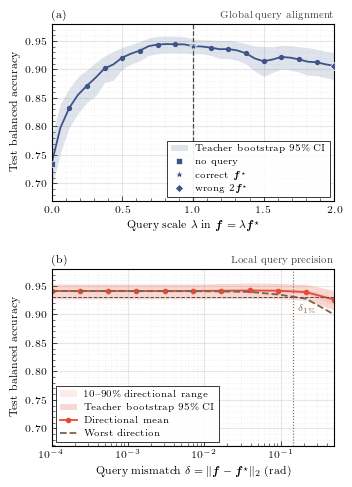

saved ../figures/fig_06_query_value_sensitivity.pdf and .png


In [27]:
fig, axes = plt.subplots(2, 1, figsize=(3.45, 4.90), sharey=True)

# (a) Global query alignment
axis_a = axes[0]
axis_a.fill_between(
    GLOBAL_X, GLOBAL_SUMMARY["lower"], GLOBAL_SUMMARY["upper"],
    color=COLORS["global"], alpha=0.16, lw=0, label=r"Teacher bootstrap 95\% CI",
)
axis_a.plot(
    GLOBAL_X, GLOBAL_SUMMARY["mean"], "-o",
    color=COLORS["global"], ms=2.8, markevery=max(1, len(GLOBAL_X) // 16),
)
axis_a.axvline(1.0, color=COLORS["reference"], lw=0.9, ls="--")

# Mark the no-query, correct-query and wrong-query points.
for lam, marker, label in [
    (0.0, "s", "no query"),
    (1.0, "*", r"correct $\boldsymbol{f}^\star$"),
    (2.0, "D", r"wrong $2\boldsymbol{f}^\star$"),
]:
    idx = int(np.argmin(np.abs(GLOBAL_X - lam)))
    axis_a.plot(
        GLOBAL_X[idx], GLOBAL_SUMMARY["mean"][idx], marker=marker,
        color=COLORS["global"], mec="white", mew=0.45,
        ms=6 if marker == "*" else 4, ls="none", label=label, zorder=5,
    )

axis_a.set_xlim(0.0, 2.0)
axis_a.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
axis_a.set_xlabel(r"Query scale $\lambda$ in $\boldsymbol{f}=\lambda\boldsymbol{f}^\star$")
axis_a.set_ylabel("Test balanced accuracy")
panel_title(axis_a, "(a)", "Global query alignment")
finish_axis(axis_a, x_minor=True)
leg_a = axis_a.legend(
    loc="lower right", frameon=True, framealpha=0.9, edgecolor="black", fancybox=False
)
leg_a.get_frame().set_linewidth(0.6)

# (b) Local query precision
axis_b = axes[1]
axis_b.fill_between(
    LOCAL_X, DIRECTION_LOWER, DIRECTION_UPPER,
    color=COLORS["local"], alpha=0.10, lw=0, label=r"10--90\% directional range",
)
axis_b.fill_between(
    LOCAL_X, LOCAL_MEAN_SUMMARY["lower"], LOCAL_MEAN_SUMMARY["upper"],
    color=COLORS["local"], alpha=0.22, lw=0, label=r"Teacher bootstrap 95\% CI",
)
axis_b.plot(
    LOCAL_X, LOCAL_MEAN_SUMMARY["mean"], "-o",
    color=COLORS["local"], ms=3.0, label="Directional mean",
)
axis_b.plot(
    LOCAL_X, LOCAL_WORST_SUMMARY["mean"], "--", color=COLORS["worst"], label="Worst direction"
)
axis_b.axhline(A_THRESHOLD, color=COLORS["reference"], lw=0.7, ls="--")
axis_b.axvline(DELTA_TOLERANCE, color=COLORS["worst"], lw=0.8, ls=":")

if TOLERANCE_STATUS == "resolved":
    tolerance_label = r"$\delta_{1\%}$"
elif TOLERANCE_STATUS == "lower_bound":
    tolerance_label = r"$\delta_{1\%}>\delta_{\max}$"
else:
    tolerance_label = r"$\delta_{1\%}<\delta_{\min}$"

axis_b.annotate(
    tolerance_label,
    xy=(DELTA_TOLERANCE, A_THRESHOLD),
    xytext=(-5 if TOLERANCE_STATUS == "lower_bound" else 4, -11),
    textcoords="offset points",
    fontsize=7,
    color=COLORS["worst"],
    ha="right" if TOLERANCE_STATUS == "lower_bound" else "left",
)
axis_b.set_xscale("log")
axis_b.set_xlim(LOCAL_X.min(), LOCAL_X.max())
axis_b.set_xlabel(r"Query mismatch $\delta=\|\boldsymbol{f}-\boldsymbol{f}^\star\|_2$ (rad)")
axis_b.set_ylabel("Test balanced accuracy")
panel_title(axis_b, "(b)", "Local query precision")
finish_axis(axis_b, x_minor=True)
leg_b = axis_b.legend(
    loc="lower left", frameon=True, framealpha=0.9, edgecolor="black", fancybox=False
)
leg_b.get_frame().set_linewidth(0.6)

# One y-range for both panels that covers all bands and the threshold.
all_lower = np.concatenate([GLOBAL_SUMMARY["lower"], LOCAL_MEAN_SUMMARY["lower"], [A_THRESHOLD]])
all_upper = np.concatenate([GLOBAL_SUMMARY["upper"], LOCAL_MEAN_SUMMARY["upper"], [A_STAR]])
y_pad = max(0.015, 0.08 * (all_upper.max() - all_lower.min()))
axes[0].set_ylim(max(0.45, all_lower.min() - y_pad), min(1.01, all_upper.max() + y_pad))

fig.subplots_adjust(left=0.165, right=0.985, bottom=0.078, top=0.940, hspace=0.38)

FIGURE_STEM = FIGURES_DIR / (
    "fig_06_query_value_sensitivity" + ("" if PROFILE == "paper" else "_smoke")
)
fig.savefig(FIGURE_STEM.with_suffix(".pdf"), pad_inches=0.05, bbox_inches="tight")
fig.savefig(FIGURE_STEM.with_suffix(".png"), dpi=600, pad_inches=0.05, bbox_inches="tight")

if USE_TEX_REQUESTED and not USE_TEX:
    print(
        "Note: usetex was requested but this installation cannot serve it; "
        "the figure was rendered with mathtext instead."
    )

plt.show()
print(f"saved {FIGURE_STEM.with_suffix('.pdf')} and .png")

## Summary

We store the teacher-bootstrap summaries plotted in the figure as CSV files and collect the matched-query accuracy $A^\star$, the nominal maximum along the ray $\boldsymbol f(\lambda)=\lambda\boldsymbol f^\star$, and the tolerance $\delta_{1\%}$ with its paired teacher-bootstrap 95% interval in a JSON record. The global scan only probes the predeclared ray; together with the direction-resolved local scan it characterizes alignment along that path and local sensitivity around $\boldsymbol f^\star$, not uniqueness over the whole two-dimensional query torus.

In [28]:
global_table = pd.DataFrame(
    {
        "query_scale": GLOBAL_X,
        "mean": GLOBAL_SUMMARY["mean"],
        "lower95": GLOBAL_SUMMARY["lower"],
        "upper95": GLOBAL_SUMMARY["upper"],
    }
)
local_table = pd.DataFrame(
    {
        "delta": LOCAL_X,
        "directional_mean": LOCAL_MEAN_SUMMARY["mean"],
        "mean_lower95": LOCAL_MEAN_SUMMARY["lower"],
        "mean_upper95": LOCAL_MEAN_SUMMARY["upper"],
        "direction_q10": DIRECTION_LOWER,
        "direction_q90": DIRECTION_UPPER,
        "worst_direction": LOCAL_WORST_SUMMARY["mean"],
        "worst_lower95": LOCAL_WORST_SUMMARY["lower"],
        "worst_upper95": LOCAL_WORST_SUMMARY["upper"],
    }
)

global_table.to_csv(
    RESULTS_DIR / f"global_summary_{PROFILE}_{RUN_ID}.csv", index=False
)
local_table.to_csv(
    RESULTS_DIR / f"local_summary_{PROFILE}_{RUN_ID}.csv", index=False
)

tolerance_summary = {
    "A_star": A_STAR,
    "global_peak_scale": GLOBAL_PEAK_SCALE,
    "global_peak_accuracy": GLOBAL_PEAK_ACCURACY,
    "accuracy_drop": ACCURACY_DROP,
    "threshold": A_THRESHOLD,
    "delta_tolerance_rad": DELTA_TOLERANCE,
    "status": TOLERANCE_STATUS,
    "bootstrap_lower95": float(TOLERANCE_CI[0]),
    "bootstrap_upper95": float(TOLERANCE_CI[1]),
    "bootstrap_censoring_counts": {
        status: int(tolerance_statuses.count(status))
        for status in sorted(set(tolerance_statuses))
    },
}
(RESULTS_DIR / f"tolerance_{PROFILE}_{RUN_ID}.json").write_text(
    json.dumps(tolerance_summary, indent=2)
)

display(global_table)
display(local_table)
print(json.dumps(tolerance_summary, indent=2))
lam1 = int(np.argmin(np.abs(GLOBAL_X - 1.0)))
print(
    f"lambda=1 teacher-bootstrap 95% CI: [{GLOBAL_SUMMARY['lower'][lam1]:.4f}, "
    f"{GLOBAL_SUMMARY['upper'][lam1]:.4f}]"
)

,query_scale,mean,lower95,upper95
0,0.0000,0.734112,0.690182,0.780809
1,0.0625,0.797519,0.752832,0.839659
2,0.1250,0.832373,0.798348,0.866735
3,0.1875,0.855626,0.823090,0.887245
4,0.2500,0.871496,0.842005,0.899310
5,0.3125,0.885784,0.854004,0.912574
6,0.3750,0.901894,0.877153,0.923766
7,0.4375,0.908939,0.881031,0.931799
8,0.5000,0.920946,0.900653,0.938551
9,0.5625,0.927802,0.909475,0.943778


,delta,directional_mean,mean_lower95,mean_upper95,direction_q10,direction_q90,worst_direction,worst_lower95,worst_upper95
0,0.000100,0.941059,0.927197,0.953349,0.941055,0.941063,0.941047,0.927383,0.953563
1,0.000234,0.941061,0.927201,0.953352,0.941056,0.941067,0.941043,0.927378,0.953554
2,0.000549,0.941056,0.927196,0.953344,0.941049,0.941062,0.941023,0.927354,0.953527
3,0.001287,0.941054,0.927194,0.953348,0.941048,0.941068,0.940981,0.927323,0.953477
4,0.003017,0.941049,0.927186,0.953347,0.941036,0.941065,0.940899,0.927229,0.953375
5,0.007071,0.941177,0.927439,0.953357,0.940994,0.941416,0.940792,0.927149,0.953258
6,0.016572,0.941538,0.927704,0.954116,0.941016,0.941963,0.940403,0.926841,0.952803
7,0.038840,0.941986,0.927843,0.954919,0.941183,0.943279,0.939460,0.926014,0.951772
8,0.091028,0.941633,0.927522,0.954391,0.939415,0.943810,0.934959,0.921520,0.948031
9,0.213340,0.939164,0.924643,0.952576,0.936005,0.943613,0.927597,0.912881,0.942496


{
  "A_star": 0.9410589321387397,
  "global_peak_scale": 0.8125,
  "global_peak_accuracy": 0.9446506836087648,
  "accuracy_drop": 0.01,
  "threshold": 0.9310589321387397,
  "delta_tolerance_rad": 0.14293334123753443,
  "status": "resolved",
  "bootstrap_lower95": 0.10596165791718,
  "bootstrap_upper95": 0.23289495531863774,
  "bootstrap_censoring_counts": {
    "resolved": 5000
  }
}
lambda=1 teacher-bootstrap 95% CI: [0.9275, 0.9534]


With the paper profile the matched query gives $A^\star=0.941$. The nominal maximum along the ray lies at $\lambda=0.8125$ with a balanced accuracy of 0.945, inside the 95% interval [0.928, 0.953] of the $\lambda=1$ point, while no query and the wrong query reach 0.734 and 0.906. Around $\boldsymbol f^\star$ the directional mean stays within 0.002 of $A^\star$ up to $\delta\approx0.2$ rad, and the worst-direction accuracy stays within one percentage point of $A^\star$ up to $\delta_{1\%}=0.14$ rad (95% interval [0.11, 0.23] rad).